# 01 · Análise exploratória / Exploratory data analysis

**Objetivo:** entender a estrutura do dataset antes de modelar: tempo de casa (`stag`),
evento de saída (`event`), proporção de **censura** e distribuição das covariáveis.

> Em análise de sobrevivência, funcionários com `event = 0` **não** são "quem ficou para sempre":
> são observações **censuradas à direita**. Sabemos apenas que ficaram *pelo menos* `stag` meses.
> Por isso médias simples de tempo de casa são enviesadas, e é aí que entram os métodos de sobrevivência.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))  # works even without `pip install -e .`
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from turnover_survival import config, data, nonparametric, models, evaluation

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
T, E = config.DURATION_COL, config.EVENT_COL

df = data.load_clean()
print(f"{len(df)} employees | {df[E].sum()} left | {1 - df[E].mean():.1%} censored")

1116 employees | 560 left | 49.8% censored


In [2]:
df.head()

,stag,event,gender,age,industry,profession,traffic,coach,head_gender,greywage,way,extraversion,independ,selfcontrol,anxiety,novator,profile_id
0,7.031,1,m,35.000,banks,hr,rabrecnerab,no,f,white,bus,6.200,4.100,5.700,7.100,8.300,486
1,22.965,1,m,33.000,banks,hr,empjs,no,m,white,bus,6.200,4.100,5.700,7.100,8.300,486
2,15.934,1,f,35.000,powergeneration,hr,rabrecnerab,no,m,white,bus,6.200,6.200,2.600,4.800,8.300,537
3,15.934,1,f,35.000,powergeneration,hr,rabrecnerab,no,m,white,bus,5.400,7.600,4.900,2.500,6.700,431
4,8.411,1,m,32.000,retail,commercial,youjs,yes,f,white,bus,3.000,4.100,8.000,7.100,3.700,50


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1116 entries, 0 to 1115
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   stag          1116 non-null   float64
 1   event         1116 non-null   int64  
 2   gender        1116 non-null   object 
 3   age           1116 non-null   float64
 4   industry      1116 non-null   object 
 5   profession    1116 non-null   object 
 6   traffic       1116 non-null   object 
 7   coach         1116 non-null   object 
 8   head_gender   1116 non-null   object 
 9   greywage      1116 non-null   object 
 10  way           1116 non-null   object 
 11  extraversion  1116 non-null   float64
 12  independ      1116 non-null   float64
 13  selfcontrol   1116 non-null   float64
 14  anxiety       1116 non-null   float64
 15  novator       1116 non-null   float64
 16  profile_id    1116 non-null   int64  
dtypes: float64(7), int64(2), object(8)
memory usage: 148.3+ KB


## Alvo de sobrevivência / Survival target

,n
event,
left,560
censored (still employed),556


,count,mean,std,min,25%,50%,75%,max
event,,,,,,,,
0,556.000,38.341,35.268,0.493,11.729,27.433,53.125,179.450
1,560.000,35.074,33.001,0.394,11.696,23.754,49.503,166.275


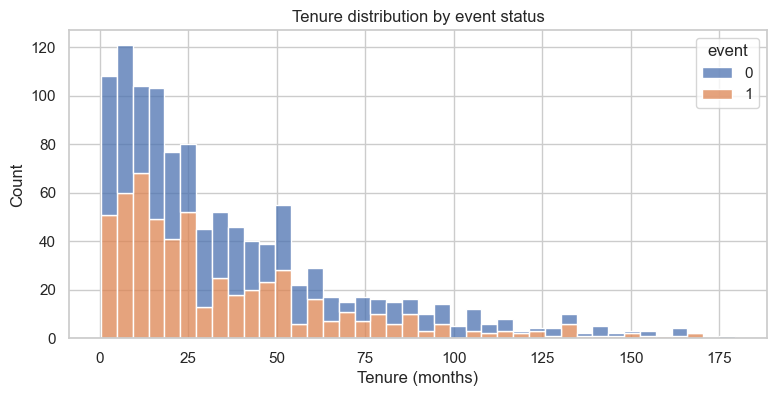

In [4]:
display(df[E].value_counts().rename(index={0: "censored (still employed)", 1: "left"}).to_frame("n"))
display(df.groupby(E)[T].describe())

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x=T, hue=E, bins=40, multiple="stack", ax=ax)
ax.set(xlabel="Tenure (months)", title="Tenure distribution by event status")
fig.savefig(config.FIGURES_DIR / "01_tenure_hist.png", dpi=120, bbox_inches="tight")

**Por que não usar a média do `stag` de quem saiu?** Ela ignora os censurados e subestima a
permanência; a mediana de Kaplan-Meier (notebook 02) é o estimador correto.

## Covariáveis categóricas / Categorical covariates

In [5]:
for col in config.CATEGORICAL_COLS:
    tab = df.groupby(col).agg(n=(E, "size"), turnover_rate=(E, "mean"), median_tenure=(T, "median"))
    display(tab.sort_values("n", ascending=False).style.format({"turnover_rate": "{:.1%}", "median_tenure": "{:.1f}"}).set_caption(col))

,n,turnover_rate,median_tenure
gender,,,
f,841,50.7%,24.0
m,275,48.7%,28.8


,n,turnover_rate,median_tenure
industry,,,
retail,283,45.9%,27.6
manufacture,143,48.3%,24.9
it,122,27.9%,24.1
banks,112,66.1%,19.1
etc,94,57.4%,27.0
consult,74,60.8%,22.7
state,55,63.6%,24.2
building,41,75.6%,23.8
transport,38,42.1%,24.0


,n,turnover_rate,median_tenure
profession,,,
hr,745,46.6%,24.3
it,74,33.8%,30.7
sales,65,52.3%,17.0
etc,37,54.1%,26.3
marketing,31,67.7%,21.4
businessdevelopment,27,59.3%,34.6
consult,25,64.0%,24.0
commercial,23,65.2%,14.5
manage,22,68.2%,18.0


,n,turnover_rate,median_tenure
traffic,,,
youjs,316,44.0%,21.9
empjs,247,52.2%,19.9
rabrecnerab,206,60.2%,26.8
friends,116,34.5%,23.6
referal,95,66.3%,40.9
ka,65,52.3%,37.1
recnerab,38,47.4%,36.0
advert,33,39.4%,15.7


,n,turnover_rate,median_tenure
coach,,,
no,674,50.7%,23.5
my head,311,46.3%,27.6
yes,131,56.5%,27.4


,n,turnover_rate,median_tenure
head_gender,,,
m,575,52.2%,24.2
f,541,48.1%,26.1


,n,turnover_rate,median_tenure
greywage,,,
white,991,49.3%,26.8
grey,125,56.8%,15.3


,n,turnover_rate,median_tenure
way,,,
bus,676,51.8%,23.9
car,325,51.7%,32.5
foot,115,36.5%,26.0


> A taxa bruta de saída (`turnover_rate`) **não** controla o tempo de exposição: um grupo com
> funcionários mais novos parece ter menos saídas apenas porque foi observado por menos tempo.
> Use-a só como orientação inicial.

## Covariáveis numéricas / Numeric covariates

,count,mean,std,min,25%,50%,75%,max
age,1116.000,31.025,6.973,18.000,26.000,30.000,36.000,58.000
extraversion,1116.000,5.590,1.857,1.000,4.600,5.400,7.000,10.000
independ,1116.000,5.474,1.702,1.000,4.100,5.500,6.900,10.000
selfcontrol,1116.000,5.608,1.986,1.000,4.100,5.700,7.200,10.000
anxiety,1116.000,5.667,1.711,1.700,4.800,5.600,7.100,10.000
novator,1116.000,5.877,1.904,1.000,4.400,6.000,7.500,10.000


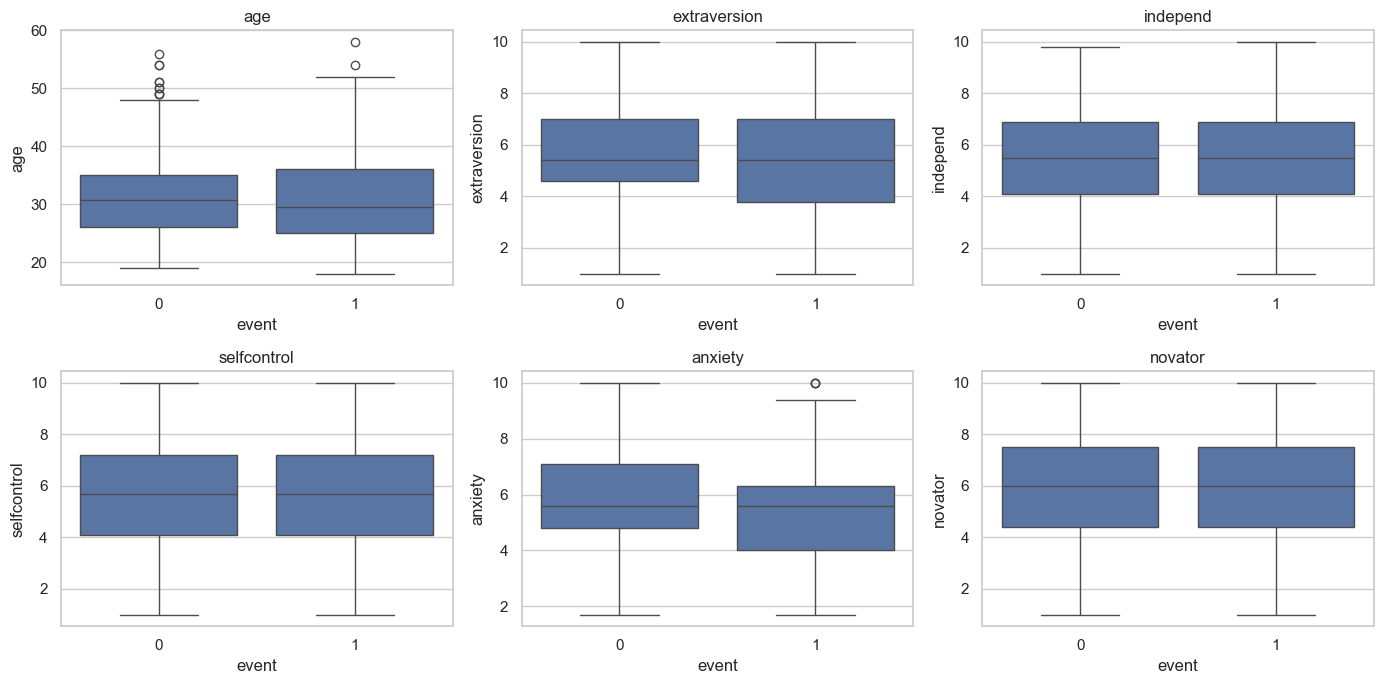

In [6]:
display(df[config.NUMERIC_COLS].describe().T)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), config.NUMERIC_COLS):
    sns.boxplot(data=df, x=E, y=col, ax=ax)
    ax.set_title(col)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "01_numeric_by_event.png", dpi=120, bbox_inches="tight")

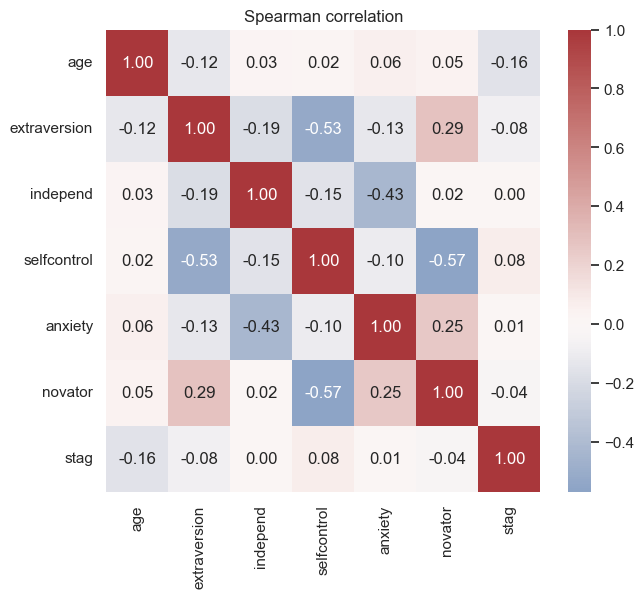

In [7]:
corr = df[config.NUMERIC_COLS + [T]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Spearman correlation")
fig.savefig(config.FIGURES_DIR / "01_corr.png", dpi=120, bbox_inches="tight")

## Categorias raras / Rare categories

In [8]:
rare = {c: df[c].value_counts()[lambda s: s < config.MIN_CATEGORY_FREQ].to_dict() for c in config.CATEGORICAL_COLS}
{k: v for k, v in rare.items() if v}

{'industry': {'pharma': 19, 'agriculture': 15, 'realestate': 13, 'horeca': 11},
 'profession': {'finance': 17,
  'engineer': 15,
  'teaching': 12,
  'accounting': 10,
  'law': 7,
  'pr': 6}}

Categorias com menos de `config.MIN_CATEGORY_FREQ` observações serão agrupadas em `other` na
matriz de modelagem (`data.make_design_matrix`) para evitar coeficientes instáveis no Cox.

### Conclusões / Takeaways
> _Preencha após rodar com os dados reais. / Fill in after running on the real data._